# 2. Data Understanding: Eksplorasi dan Pemahaman Citra Satelit Sentinel-2 L2A

Tahap **Data Understanding** dalam metodologi **CRISP-DM** bertujuan untuk memahami karakteristik data citra satelit yang diperoleh, memverifikasi kualitas sampel lapangan (*ground truth*), memeriksa integritas statistik sebaran data, serta mengidentifikasi pola fisik pantulan spektral dari masing-masing kelas tutupan lahan di wilayah Provinsi Jawa Timur.

---

### Kebutuhan Data dan Parameter Teknis:
1. **Sensor dan Misi Satelit**: Satelit Copernicus Sentinel-2 Multi-Spectral Instrument (MSI), dikelola oleh European Space Agency (ESA).
2. **Tingkat Pemrosesan Citra (*Processing Level*)**: Sentinel-2 Level-2A (L2A), yang menyediakan data pantulan permukaan tanah (*Bottom-of-Atmosphere / BOA Surface Reflectance*) yang telah terkoreksi secara geometrik dan radiometrik dari gangguan atmosfer.
3. **Pita Spektral (*Bands*) yang Digunakan**: 7 pita spektral dengan resolusi spasial 10 meter hingga 20 meter:
   * **B02 (Blue, 490 nm)**: Cahaya tampak biru (resolusi 10m).
   * **B03 (Green, 560 nm)**: Cahaya tampak hijau (resolusi 10m).
   * **B04 (Red, 665 nm)**: Cahaya tampak merah (resolusi 10m).
   * **B08 (Broad NIR, 842 nm)**: Inframerah dekat lebar (resolusi 10m).
   * **B8A (Narrow NIR, 865 nm)**: Inframerah dekat sempit / tepi merah (resolusi 20m).
   * **B11 (SWIR-1, 1610 nm)**: Inframerah gelombang pendek 1 (resolusi 20m).
   * **B12 (SWIR-2, 2190 nm)**: Inframerah gelombang pendek 2 (resolusi 20m).
4. **Metode Pengambilan Sampel (*Ground Truth Sampling*)**: Digitasi 250 poligon representatif (50 sampel per kelas seimbang sempurna) di berbagai kabupaten/kota di Jawa Timur, yang disimpan dalam format GeoJSON.
5. **Mekanisme Ekstraksi Reflektansi**: Menggunakan skrip Python terintegrasi ([extract_sentinel2_samples.py](file:///d:/university/semester%205_book/proyek%20sain%20data/src/Tugas_UTS/2-data_understanding/extract_sentinel2_samples.py)) yang terhubung ke **Copernicus Data Space Ecosystem (CDSE) Sentinel Hub Process API** untuk mengunduh nilai piksel dan poligon bebas awan (*cloud coverage < 5%*).


In [1]:
import os
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
from rasterio.plot import show
from dotenv import load_dotenv

# Set style visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('[OK] Seluruh library berhasil dimuat.')

[OK] Seluruh library berhasil dimuat.


## 2.1 Pemuatan Data Sampel Poligon dan Dataset Piksel

Pada tahap ini, kita memuat dua tingkatan dataset hasil ekstraksi:
1. **Dataset Poligon (`sentinel2_sample_polygons.csv`)**: Terdiri dari 250 baris data poligon, di mana setiap baris mewakili nilai rata-rata pantulan spektral dari sebuah poligon tutupan lahan yang telah divalidasi kebenaran lapangannya.
2. **Dataset Piksel (`sentinel2_pixels_dataset.csv`)**: Terdiri dari 12.500 baris sampel piksel individu (50 piksel diekstrak secara merata dari masing-masing 250 poligon) untuk analisis granularitas spektral tingkat tinggi.

> Catatan Metodologi:
> Karena setiap kelas memiliki jumlah sampel yang sama persis (50 sampel per kelas pada data poligon), dataset ini tergolong seimbang sempurna (*balanced dataset*). Kondisi ini menguntungkan karena model klasifikasi terbebas dari bias kelas mayoritas tanpa memerlukan penambahan data sintetis (seperti SMOTE) yang berisiko mengubah nilai fisik pantulan spektral asli.


In [2]:
data_dir = 'extracted_data'
df_poly = pd.read_csv(os.path.join(data_dir, 'sentinel2_sample_polygons.csv'))
df_pixels = pd.read_csv(os.path.join(data_dir, 'sentinel2_pixels_dataset.csv'))

print(f'Jumlah Sampel Poligon: {len(df_poly)} baris')
print(f'Jumlah Sampel Piksel : {len(df_pixels)} baris')
print('\nDistribusi Sampel Poligon per Kelas:')
display(df_poly['class_name'].value_counts())

Jumlah Sampel Poligon: 250 baris
Jumlah Sampel Piksel : 12500 baris

Distribusi Sampel Poligon per Kelas:


class_name
bangunan     50
hutan        50
mangrove     50
perairan     50
pertanian    50
Name: count, dtype: int64

## 2.2 Analisis Statistik Spektral dan Indeks Berdasarkan Kelas

Tabel di bawah ini menyajikan nilai rata-rata pantulan spektral (*mean reflectance*) serta nilai indeks turunan untuk setiap kategori tutupan lahan di Jawa Timur.

### Karakteristik Fisis Saluran Spektral & Indeks:
* **B02, B03, B04 (Visible Spectrum)**: Menangkap radiasi cahaya tampak; berguna untuk mendeteksi warna alami objek.
* **B08 & B8A (Near-Infrared - NIR)**: Memiliki interaksi kuat dengan struktur sel spons pada daun tanaman yang sehat; menghasilkan hamburan radiasi tinggi pada kanopi hijau.
* **B11 & B12 (Short-Wave Infrared - SWIR)**: Menyerap radiasi secara kuat pada media air dan substrat lembap, namun memantulkan radiasi tinggi pada material buatan kering (semen, genteng, aspal).
* **NDVI (*Normalized Difference Vegetation Index*)**: Mengukur tingkat kehijauan dan biomassa kanopi vegetasi aktif.
* **MNDWI (*Modified Normalized Difference Water Index*)**: Mengisolasi badan air permukaan terbuka dari latar belakang daratan.
* **NDBI (*Normalized Difference Built-up Index*)**: Menyorot kerapatan infrastruktur fisik dan material buatan manusia.


In [3]:
bands_and_indices = ['B02', 'B03', 'B04', 'B08', 'B8A', 'B11', 'B12', 'NDVI', 'MNDWI', 'NDBI', 'Mangrove_Index_8A_11_4']
summary_table = df_poly.groupby('class_name')[bands_and_indices].mean().reset_index()
display(summary_table.round(4))

,class_name,B02,B03,B04,B08,B8A,B11,B12,NDVI,MNDWI,NDBI,Mangrove_Index_8A_11_4
0,bangunan,0.1678,0.1844,0.2071,0.2491,0.2596,0.3084,0.2912,0.1157,-0.2907,0.1095,0.2038
1,hutan,0.1649,0.1759,0.1672,0.3358,0.3527,0.2646,0.1867,0.5019,-0.3593,-0.1467,1.0012
2,mangrove,0.1003,0.1172,0.0910,0.3144,0.3218,0.1576,0.0873,0.6650,-0.2712,-0.3554,1.8964
3,perairan,0.1058,0.1135,0.0975,0.0863,0.0913,0.0784,0.0635,-0.0535,0.1881,-0.0642,-0.2838
4,pertanian,0.0770,0.1036,0.1132,0.2436,0.2598,0.2339,0.1658,0.3802,-0.3692,-0.0410,0.7156


## 2.3 Profil Tanda Tangan Spektral (*Spectral Signatures*)

Setiap objek di permukaan bumi memiliki kurva tanda tangan spektral (*spectral signature*) yang khas, mencerminkan respon fisika material tersebut terhadap berbagai rentang panjang gelombang elektromagnetik:

* **Perairan (*Water Body*)**: Menunjukkan kurva menurun tajam. Cahaya tampak biru dan hijau masih sedikit dipantulkan, namun gelombang inframerah (NIR dan SWIR) hampir seluruhnya diserap oleh molekul air murni (nilai mendekati 0.00 hingga 0.05).
* **Bangunan (*Built-up*)**: Menunjukkan tren pantulan yang meningkat secara bertahap dari spektrum tampak hingga mencapai puncaknya pada gelombang SWIR-1 (Band 11 $\approx 0.30$) akibat sifat termal dan material semen/keramik kering.
* **Vegetasi (Hutan, Mangrove, Pertanian)**: Memiliki fenomena fisik *Red Edge*, yaitu penyerapan kuat pada pita merah (Band 4) oleh pigmen klorofil untuk fotosintesis, diikuti lonjakan tajam pantulan pada inframerah dekat (Band 8 dan 8A) akibat struktur internal sel mesofil daun.


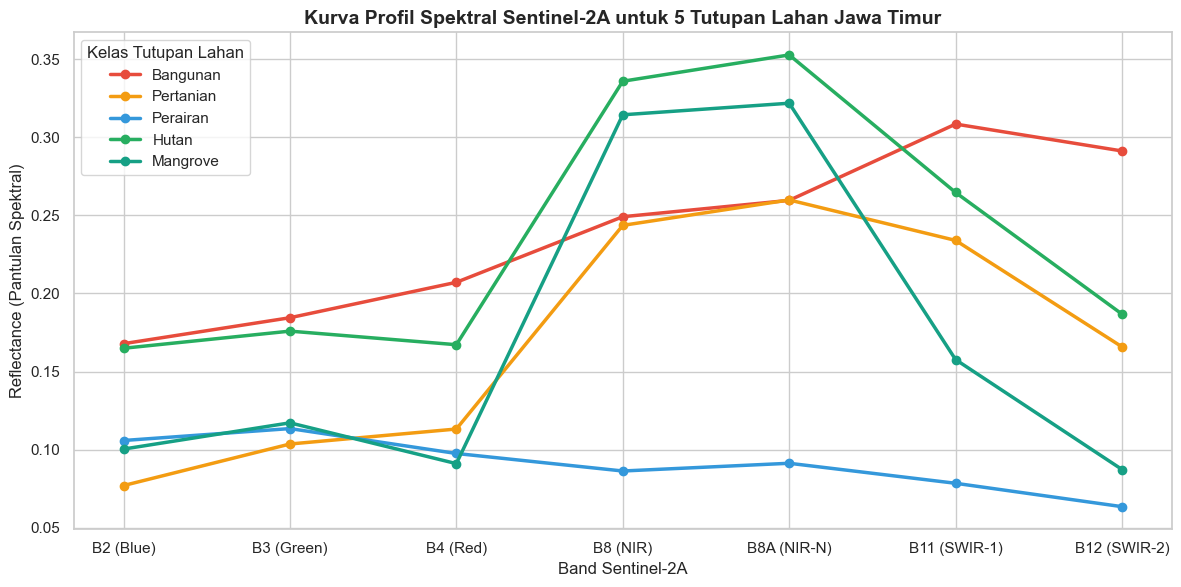

In [4]:
band_cols = ['B02', 'B03', 'B04', 'B08', 'B8A', 'B11', 'B12']
band_names = ['B2 (Blue)', 'B3 (Green)', 'B4 (Red)', 'B8 (NIR)', 'B8A (NIR-N)', 'B11 (SWIR-1)', 'B12 (SWIR-2)']
palette = {'bangunan': '#e74c3c', 'pertanian': '#f39c12', 'perairan': '#3498db', 'hutan': '#27ae60', 'mangrove': '#16a085'}

fig, ax = plt.subplots(figsize=(12, 6))
for cls in ['bangunan', 'pertanian', 'perairan', 'hutan', 'mangrove']:
    cls_data = df_poly[df_poly['class_name'] == cls][band_cols].mean()
    ax.plot(band_names, cls_data.values, marker='o', linewidth=2.5, label=cls.capitalize(), color=palette[cls])

ax.set_title('Kurva Profil Spektral Sentinel-2A untuk 5 Tutupan Lahan Jawa Timur', fontsize=14, fontweight='bold')
ax.set_xlabel('Band Sentinel-2A', fontsize=12)
ax.set_ylabel('Reflectance (Pantulan Spektral)', fontsize=12)
ax.legend(title='Kelas Tutupan Lahan', fontsize=11)
plt.tight_layout()
plt.show()

## 2.4 Analisis Karakteristik Khusus: Band 8A, Band 11, dan Band 4 (Hutan vs Mangrove)

Salah satu tantangan ilmiah utama dalam klasifikasi tutupan lahan di wilayah pesisir Jawa Timur adalah **membedakan Hutan Daratan Biasa dengan Hutan Mangrove**. Jika klasifikasi hanya didasarkan pada indeks vegetasi umum (seperti NDVI), kedua kelas ini kerap tumpang tindih (*spectral overlapping*) karena kanopi keduanya sama-sama lebat dan hijau.

### Penjelasan Ilmiah Efektivitas Kombinasi Band 8A - 11 - 4:
1. **Perbedaan Reflektansi SWIR-1 (Band 11)**: Hutan mangrove tumbuh di zona intertidal dengan tanah rawa berlumpur jenuh air. Molekul air pada lumpur pasang-surut menyerap radiasi inframerah gelombang pendek secara kuat, sehingga **nilai reflektansi Band 11 pada mangrove secara konsisten jauh lebih rendah ($\approx 0.14 - 0.16$) dibandingkan hutan daratan ($\approx 0.24 - 0.28$)**.
2. **Kerapatan Spektral Red-Edge (Band 8A)**: Band 8A memiliki lebar saluran sempit (865 nm) yang bebas dari pengaruh serapan uap air atmosferik, memberikan nilai pantulan yang stabil dan murni dari kanopi vegetasi mangrove.
3. **Formulasi Mangrove Index $\left(\frac{B8A - B04}{B11}\right)$**: Rasio ini memaksimalkan kontras antara respon biomassa vegetasi aktif $(B8A - B04)$ terhadap penyerapan air substrat di bawah kanopi $(B11)$. Nilai indeks ini secara fisik menghasilkan skor tinggi pada ekosistem mangrove dan membedakannya secara tegas dari hutan daratan kering.


C:\Users\user\AppData\Local\Temp\ipykernel_15188\3228867083.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_poly, x='class_name', y='Mangrove_Index_8A_11_4', palette=palette, ax=axes[1])


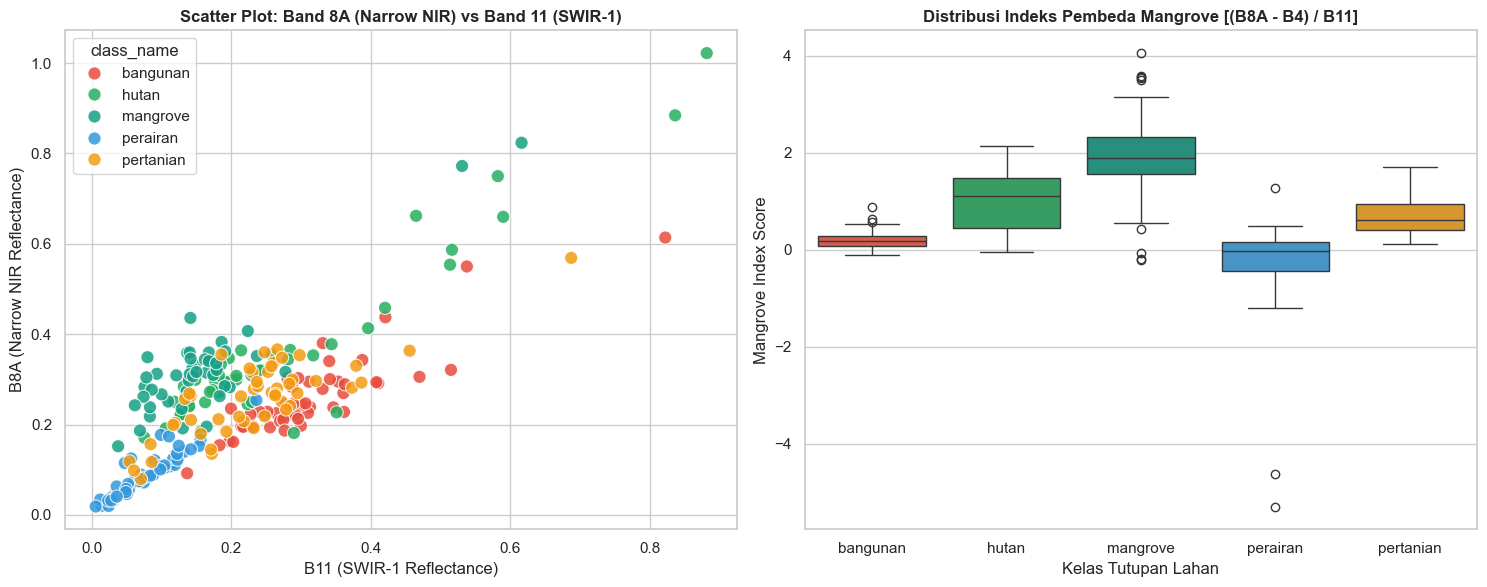

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scatter plot Band 8A vs Band 11
sns.scatterplot(data=df_poly, x='B11', y='B8A', hue='class_name', palette=palette, s=90, alpha=0.85, ax=axes[0])
axes[0].set_title('Scatter Plot: Band 8A (Narrow NIR) vs Band 11 (SWIR-1)', fontweight='bold')
axes[0].set_xlabel('B11 (SWIR-1 Reflectance)')
axes[0].set_ylabel('B8A (Narrow NIR Reflectance)')

# Boxplot Mangrove Index (8A, 11, 4)
sns.boxplot(data=df_poly, x='class_name', y='Mangrove_Index_8A_11_4', palette=palette, ax=axes[1])
axes[1].set_title('Distribusi Indeks Pembeda Mangrove [(B8A - B4) / B11]', fontweight='bold')
axes[1].set_xlabel('Kelas Tutupan Lahan')
axes[1].set_ylabel('Mangrove Index Score')

plt.tight_layout()
plt.show()

## 2.5 Eksplorasi Visual Spasial Citra Satelit Regional Sentinel-2 (GeoTIFF)

Untuk melengkapi analisis tabular, dilakukan visualisasi spasial raster komposit citra satelit Sentinel-2 (`sentinel2_jatim_scene.tif`) yang mencakup wilayah studi Jawa Timur menggunakan dua metode komposit standar penginderaan jauh:

1. **True Color Composite (RGB: B04 - B03 - B02)**: Menampilkan warna permukaan bumi secara alami sebagaimana dilihat oleh mata manusia.
2. **False Color Infrared Composite (RGB: B08 - B04 - B03)**:
   * **Warna Merah Pekat / Menyala**: Menunjukkan vegetasi dengan kanopi klorofil aktif berkepadatan tinggi (hutan lindung dan mangrove).
   * **Warna Biru Tua / Gelap**: Mengindikasikan badan air terbuka, danau, atau laut dalam karena penyerapan NIR total.
   * **Warna Cyan / Abu-abu Terang**: Menunjukkan area permukiman perkotaan padat, jaringan jalan beton, dan lahan terbuka non-vegetasi.

Eksplorasi visual ini memastikan bahwa citra yang digunakan bebas dari gangguan awan tebal dan memiliki kontras spektral yang representatif sebelum memasuki tahap penyiapan data.


Ukuran Citra Raster: 1024 x 1024 piksel, 7 band
Sistem Koordinat (CRS): EPSG:4326
Bounding Box: BoundingBox(left=112.5, bottom=-7.6, right=113.0, top=-7.0)


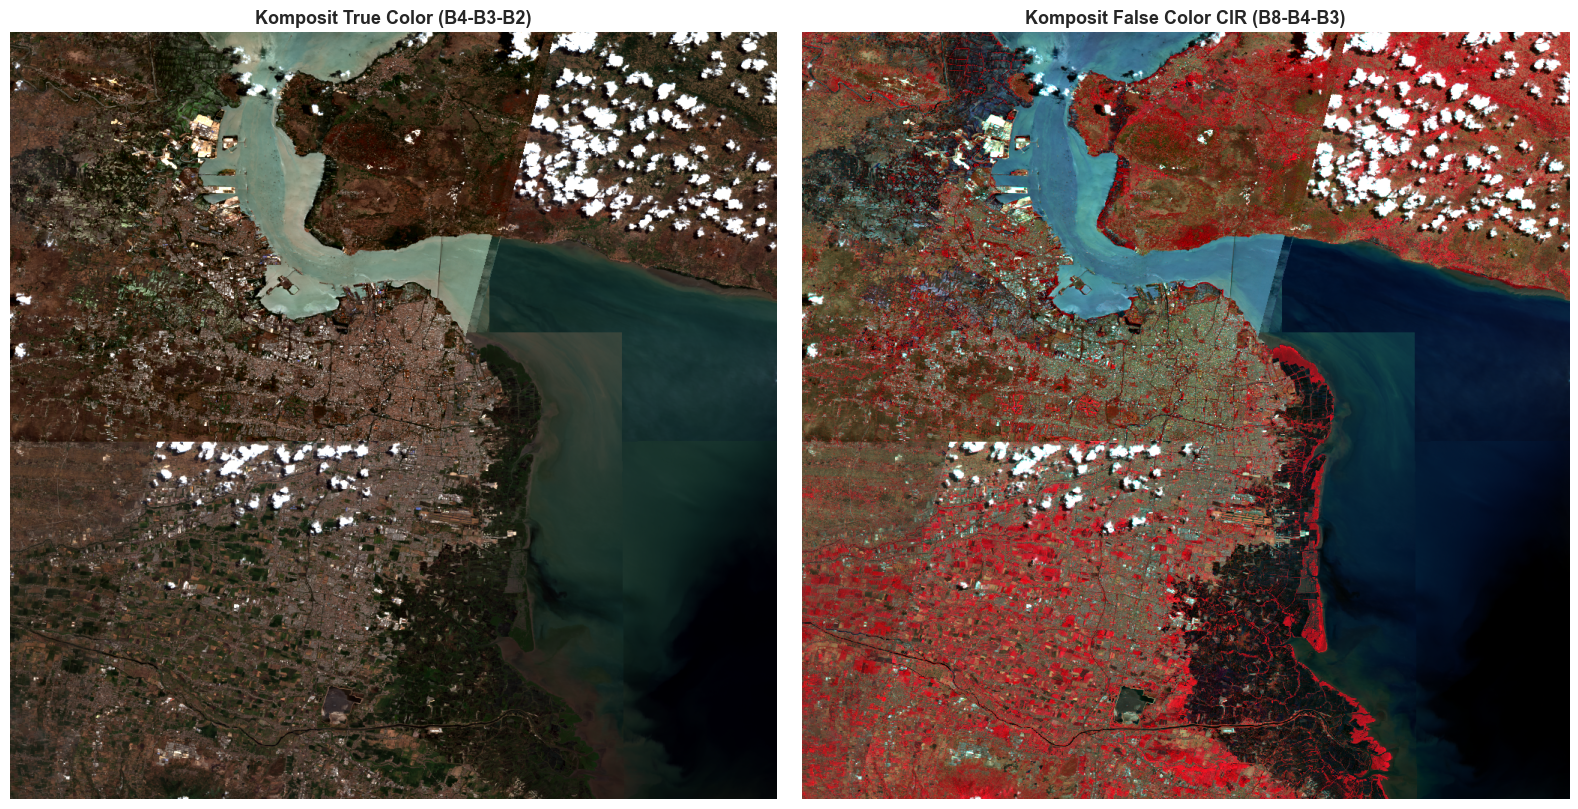

In [6]:
tif_path = os.path.join(data_dir, 'sentinel2_jatim_scene.tif')
if os.path.exists(tif_path):
    with rasterio.open(tif_path) as src:
        print(f'Ukuran Citra Raster: {src.width} x {src.height} piksel, {src.count} band')
        print(f'Sistem Koordinat (CRS): {src.crs}')
        print(f'Bounding Box: {src.bounds}')
        
        b2 = src.read(1) # Blue
        b3 = src.read(2) # Green
        b4 = src.read(3) # Red
        b8 = src.read(4) # NIR
        
        def normalize_band(b):
            b_min, b_max = np.nanpercentile(b, (2, 98))
            return np.clip((b - b_min) / (b_max - b_min + 1e-8), 0, 1)
        
        rgb_true = np.dstack([normalize_band(b4), normalize_band(b3), normalize_band(b2)])
        rgb_false = np.dstack([normalize_band(b8), normalize_band(b4), normalize_band(b3)])
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
        ax1.imshow(rgb_true)
        ax1.set_title('Komposit True Color (B4-B3-B2)', fontsize=13, fontweight='bold')
        ax1.axis('off')
        
        ax2.imshow(rgb_false)
        ax2.set_title('Komposit False Color CIR (B8-B4-B3)', fontsize=13, fontweight='bold')
        ax2.axis('off')
        
        plt.tight_layout()
        plt.show()

## 2.6 Visualisasi Geospasial: Peta 2D Interaktif Persebaran 250 Sampel Lapangan

Peta 2D interaktif ini dirancang pada tahap Data Understanding menggunakan pustaka Leaflet (Folium) untuk memvisualisasikan citra satelit resolusi tinggi serta persebaran spasial dari 250 poligon sampel representatif (50 sampel per kelas seimbang) di seluruh wilayah Jawa Timur sebelum proses klasifikasi dilakukan.

### Komponen Fungsional Peta Eksplorasi:
1. **Navigasi Spasial**: Mendukung perbesaran (*Zoom In/Out*) dan pergeseran (*Pan*) peta secara mulus di seluruh Jawa Timur.
2. **Pilihan Basemap Satelit Resolusi Tinggi**:
   * **Esri World Imagery**: Citra satelit asli beresolusi tinggi tanpa label jalan.
   * **Google Satellite Hybrid**: Citra satelit Google lengkap dengan batas administrasi dan nama wilayah.
   * **OpenStreetMap**: Peta jaringan jalan dan topografi publik.
3. **Sebaran Poligon & Titik Sampel Tematik (5 Kelas Seimbang)**:
   * **Bangunan (*Built-up*)**: 50 sampel poligon (kode warna merah `#EF4444`)
   * **Lahan Pertanian (*Farmland*)**: 50 sampel poligon (kode warna oranye/amber `#D97706`)
   * **Perairan (*Water Body*)**: 50 sampel poligon (kode warna biru samudra `#0284C7`)
   * **Hutan Daratan (*Forest*)**: 50 sampel poligon (kode warna hijau emerald `#16A34A`)
   * **Hutan Mangrove (*Mangrove*)**: 50 sampel poligon (kode warna hijau toska `#0D9488`)
4. **Popup Informasi Spektral Lengkap**: Setiap marker/poligon dapat diklik untuk memeriksa ID sampel, koordinat centroid, luas piksel, nilai reflektansi 7 band asli ($B02$ s/d $B12$), serta nilai indeks biofisik kunci ($NDVI$, $MNDWI$, $NDBI$, dan $Mangrove\ Index$).
5. **Kontrol Layer (*Layer Control*)**: Memungkinkan pengguna mengaktifkan atau menonaktifkan kategori kelas tertentu secara selektif untuk verifikasi lapangan (*ground truth verification*).


In [7]:
import os
import json
import folium
import branca
from folium import plugins
import pandas as pd

# 1. Pemuatan Data Sampel dan Inisialisasi Peta
data_dir = 'extracted_data'
geojson_dir = 'sampling_geojson'
df_poly = pd.read_csv(os.path.join(data_dir, 'sentinel2_sample_polygons.csv'))
lookup_df = df_poly.set_index('sample_id')

# Inisialisasi Peta Terpusat Jawa Timur
map_center = [-7.65, 112.5]
m = folium.Map(location=map_center, zoom_start=8, control_scale=True, tiles=None)

# 2. Basemap Layer (3 Pilihan Peta Bersih Seluruh Wilayah Jatim)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Esri World Imagery (Satelit Default)',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google Hybrid',
    name='Google Satellite Hybrid',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    'OpenStreetMap',
    name='OpenStreetMap (Peta Jalan)',
    overlay=False,
    control=True
).add_to(m)

# 3. Palet Warna Standar CRISP-DM & Sebaran 250 Poligon Sampel Se-Jawa Timur
class_configs = {
    'bangunan': {'name': 'Bangunan (Built-up)', 'color': '#EF4444', 'file': 'bangunan.geojson'},
    'pertanian': {'name': 'Lahan Pertanian (Farmland)', 'color': '#D97706', 'file': 'pertanian.geojson'},
    'perairan': {'name': 'Perairan (Water Body)', 'color': '#0284C7', 'file': 'perairan.geojson'},
    'hutan': {'name': 'Hutan Daratan (Forest)', 'color': '#16A34A', 'file': 'hutan.geojson'},
    'mangrove': {'name': 'Hutan Mangrove (Mangrove)', 'color': '#0D9488', 'file': 'mangrove.json'}
}

for class_key, conf in class_configs.items():
    fg_class = folium.FeatureGroup(name=f"{conf['name']} (50 Sampel)", show=True)
    file_path = os.path.join(geojson_dir, conf['file'])
    if os.path.exists(file_path):
        with open(file_path, 'r', encoding='utf-8') as fp:
            geo_data = json.load(fp)
        for i, feat in enumerate(geo_data.get('features', [])):
            sample_id = f'{class_key}_{i+1:03d}'
            row = lookup_df.loc[sample_id] if sample_id in lookup_df.index else None
            if row is not None:
                popup_html = (
                    f'<div style="font-family: -apple-system, BlinkMacSystemFont, Segoe UI, Roboto, sans-serif; min-width: 250px; font-size: 12px; border-radius: 8px; overflow: hidden; box-shadow: 0 2px 8px rgba(0,0,0,0.15);">'
                    f'<div style="background: {conf["color"]}; color: white; padding: 6px 10px; font-weight: 700; font-size: 13px;">{conf["name"]}</div>'
                    f'<div style="padding: 8px 10px; background: #FFFFFF; color: #1E293B; line-height: 1.5;">'
                    f'<div><b>ID Sampel:</b> <code style="background:#F1F5F9; padding:1px 4px; border-radius:3px;">{sample_id}</code></div>'
                    f'<div><b>Koordinat:</b> {row["centroid_lat"]:.4f}° LS, {row["centroid_lon"]:.4f}° BT</div>'
                    f'<div><b>Luas Sampel:</b> {int(row["pixel_count"]):,} piksel</div>'
                    f'<hr style="margin: 6px 0; border: none; border-top: 1px solid #E2E8F0;">'
                    f'<div style="font-weight: 600; color: #475569; margin-bottom: 2px;">Reflektansi Band Sentinel-2:</div>'
                    f'<div style="font-family: monospace; font-size: 11px; color: #334155;">'
                    f'B02: {row["B02"]:.3f} | B03: {row["B03"]:.3f} | B04: {row["B04"]:.3f}<br>'
                    f'B08: {row["B08"]:.3f} | B8A: {row["B8A"]:.3f}<br>'
                    f'B11: {row["B11"]:.3f} | B12: {row["B12"]:.3f}'
                    f'</div>'
                    f'<hr style="margin: 6px 0; border: none; border-top: 1px solid #E2E8F0;">'
                    f'<div style="font-weight: 600; color: #475569; margin-bottom: 2px;">Indeks Biofisik Terpilih:</div>'
                    f'<div style="font-size: 11px;">'
                    f'NDVI: <b style="color:#16A34A;">{row["NDVI"]:.3f}</b> | MNDWI: <b style="color:#0284C7;">{row["MNDWI"]:.3f}</b><br>'
                    f'Mangrove Idx: <b style="color:#0D9488;">{row["Mangrove_Index_8A_11_4"]:.3f}</b> | NDBI: <b style="color:#EF4444;">{row["NDBI"]:.3f}</b>'
                    f'</div>'
                    f'</div></div>'
                )

                # Titik Penanda Centroid (Membuat sebaran terlihat jelas dari zoom jauh)
                folium.CircleMarker(
                    location=[row['centroid_lat'], row['centroid_lon']],
                    radius=5.5,
                    color='#FFFFFF',
                    weight=1.5,
                    fill=True,
                    fill_color=conf['color'],
                    fill_opacity=0.9,
                    tooltip=f"{conf['name']}: {sample_id}",
                    popup=folium.Popup(popup_html, max_width=300)
                ).add_to(fg_class)
            else:
                popup_html = f"<b>{conf['name']}</b>: {sample_id}"

            # Poligon Sampel
            folium.GeoJson(
                feat,
                style_function=lambda x, color=conf['color']: {
                    'fillColor': color, 'color': color, 'weight': 2, 'fillOpacity': 0.4
                },
                highlight_function=lambda x: {'weight': 3.5, 'fillOpacity': 0.8},
                tooltip=f"{conf['name']}: {sample_id}",
                popup=folium.Popup(popup_html, max_width=300)
            ).add_to(fg_class)
    fg_class.add_to(m)

# 4. Kontrol Tambahan (MousePosition & Fullscreen)
plugins.MousePosition(
    position='bottomright',
    separator=' | ',
    empty_string='Arahkan kursor',
    lng_first=False,
    num_digits=4,
    prefix='Lat/Lon: '
).add_to(m)
plugins.Fullscreen(position='topleft', title='Layar Penuh', title_cancel='Keluar Layar Penuh').add_to(m)

# 5. Tombol Reset View (Jawa Timur)
reset_macro = branca.element.MacroElement()
reset_macro._template = branca.element.Template('''{% macro script(this, kwargs) %}
var resetCtrl = L.Control.extend({
    options: {position: 'topleft'},
    onAdd: function(map) {
        var c = L.DomUtil.create('div', 'leaflet-bar');
        c.innerHTML = '<a href="#" title="Reset Tampilan Jawa Timur" style="font-size:16px; font-weight:bold; line-height:26px; text-align:center; display:block; width:26px; height:26px; background:white; color:#333; text-decoration:none;">⟲</a>';
        c.onclick = function(e){
            e.preventDefault();
            map.fitBounds([[-8.4, 111.0], [-6.8, 114.5]]);
        };
        return c;
    }
});
map.addControl(new resetCtrl());
{% endmacro %}''')
m.get_root().add_child(reset_macro)

# 6. Legenda Leaflet Control Murni (Terkunci Rapi di Sudut Kiri Bawah Peta)
legend_macro = branca.element.MacroElement()
legend_macro._template = branca.element.Template('''{% macro script(this, kwargs) %}
var legendCtrl = L.Control.extend({
    options: {position: 'bottomleft'},
    onAdd: function(map) {
        var div = L.DomUtil.create('div', 'info legend');
        div.style.backgroundColor = 'rgba(255, 255, 255, 0.95)';
        div.style.padding = '8px 12px';
        div.style.borderRadius = '8px';
        div.style.boxShadow = '0 2px 8px rgba(0,0,0,0.2)';
        div.style.fontFamily = '-apple-system, BlinkMacSystemFont, Segoe UI, Roboto, sans-serif';
        div.style.fontSize = '11px';
        div.style.lineHeight = '1.6';
        div.style.minWidth = '180px';
        div.innerHTML = '<div style="font-weight:700; font-size:12px; margin-bottom:4px; color:#0F172A;">Legenda 250 Sampel Jatim</div>' +
            '<div><span style="background:#EF4444; width:10px; height:10px; display:inline-block; margin-right:6px; border-radius:50%;"></span><b>Bangunan</b> (50)</div>' +
            '<div><span style="background:#D97706; width:10px; height:10px; display:inline-block; margin-right:6px; border-radius:50%;"></span><b>Pertanian</b> (50)</div>' +
            '<div><span style="background:#0284C7; width:10px; height:10px; display:inline-block; margin-right:6px; border-radius:50%;"></span><b>Perairan</b> (50)</div>' +
            '<div><span style="background:#16A34A; width:10px; height:10px; display:inline-block; margin-right:6px; border-radius:50%;"></span><b>Hutan Daratan</b> (50)</div>' +
            '<div><span style="background:#0D9488; width:10px; height:10px; display:inline-block; margin-right:6px; border-radius:50%;"></span><b>Hutan Mangrove</b> (50)</div>';
        return div;
    }
});
map.addControl(new legendCtrl());
{% endmacro %}''')
m.get_root().add_child(legend_macro)

# 7. Layer Control (Collapsed agar rapi dan tidak menghalangi peta)
folium.LayerControl(position='topright', collapsed=True).add_to(m)

# Menampilkan Peta langsung di Notebook
m
